# Import All Needed Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.metrics import precision_recall_curve, auc

from sklearn.model_selection import train_test_split

In [2]:
# ---------------------------------------------------------------- settings
DATE_COL = "filed_date"            # first day the trade was public = first day you could act
HORIZON = pd.Timedelta(days=5)     # <- SET THIS: how many days target_return is measured over
RETURN_IN_PERCENT = True           # <- SET THIS: True if 8.55 means 8.55%, False if it means 855%
TEST_FRAC = 0.2                    # newest 20% of filings = test set
VAL_FRAC = 0.2                     # newest 20% of the training period = threshold-tuning set
USE_TICKER = False                 # ticker/company are high-cardinality; start without them
COST = 0.0005                      # 5 bps per trade (fees + slippage), adjust to your broker
RISK_FRACTION = 0.10               # fraction of equity committed per filing-day
INITIAL_CAPITAL = 2_000

In [3]:
# Load CSV
df = pd.read_csv("data/training_data_sell_in_5_days_with_time.csv")

# Parse the date and put trades in chronological order
df["filed_date"] = pd.to_datetime(df["filed_date"])
df = df.sort_values("filed_date")

# Drop duplicates (while ticker is still present, so only true copies are removed)
df = df.drop_duplicates()

# Drop unneeded features
df = df.drop(columns=["company", "ticker"])
     
# Check what dropna will remove before doing it
print(df.isna().sum()[df.isna().sum() > 0])
df = df.dropna().reset_index(drop=True)

# Add target
df["target"] = (df["target_return"] > 0).astype(int)

# Return as a fraction (assumes 8.55 means 8.55%)
df["ret"] = df["target_return"] / 100

# Features: filed_date stays out of X so the model can't memorize time periods
X = df.drop(columns=["target", "target_return", "ret", "filed_date"])
y = df["target"]

cat_cols = X.select_dtypes(include=["object", "string", "category"]).columns
num_cols = X.select_dtypes(exclude=["object", "string", "category"]).columns

print(df.head())
print(f"length of df: {len(df)}")
print(f"Date range: {df['filed_date'].min().date()} -> {df['filed_date'].max().date()}")

Series([], dtype: int64)
  transaction_type  trade_size_usd       party chamber   politician_name  \
0         Purchase          8000.5  Democratic   House         Ro Khanna   
1         Purchase          8000.5  Republican   House  Thomas Macarthur   
2         Purchase          8000.5  Republican   House  Thomas Macarthur   
3         Purchase          8000.5  Republican   House  Thomas Macarthur   
4         Purchase          8000.5  Republican   House  Thomas Macarthur   

  filed_date  days_to_file  target_return  target       ret  
0 2018-11-09            15      -2.501895       0 -0.025019  
1 2019-01-11            24       1.792991       1  0.017930  
2 2019-01-11          -344       1.792991       1  0.017930  
3 2019-01-11            23       1.792991       1  0.017930  
4 2019-01-11            22       1.792991       1  0.017930  
length of df: 16863
Date range: 2018-11-09 -> 2024-12-19


In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
import xgboost as xgb

HORIZON = pd.Timedelta(days=7)   # 5 trading days ~ 7 calendar days
TEST_FRAC = 0.2

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
        ("num", "passthrough", num_cols)
    ]
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", xgb.XGBClassifier(
        n_estimators=200,
        max_depth=5,
        learning_rate=0.05,
        scale_pos_weight=2,
        random_state=42,
        eval_metric="logloss"
    ))
])

# Chronological split: oldest 80% train, newest 20% test
split_date = df["filed_date"].iloc[int(len(df) * (1 - TEST_FRAC))]

# Purge training rows whose 5-day outcome window reaches into the test period
train_mask = df["filed_date"] < (split_date - HORIZON)
test_mask = df["filed_date"] >= split_date

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]

print(f"Train: {len(X_train)} rows ({df.loc[train_mask, 'filed_date'].min().date()} -> {df.loc[train_mask, 'filed_date'].max().date()})")
print(f"Test:  {len(X_test)} rows ({df.loc[test_mask, 'filed_date'].min().date()} -> {df.loc[test_mask, 'filed_date'].max().date()})")

model.fit(X_train, y_train)

probs = model.predict_proba(X_test)[:, 1]

print(probs)

Train: 13449 rows (2018-11-09 -> 2024-01-18)
Test:  3381 rows (2024-01-26 -> 2024-12-19)
[0.90962726 0.90780056 0.90780056 ... 0.46279156 0.46279156 0.5992503 ]


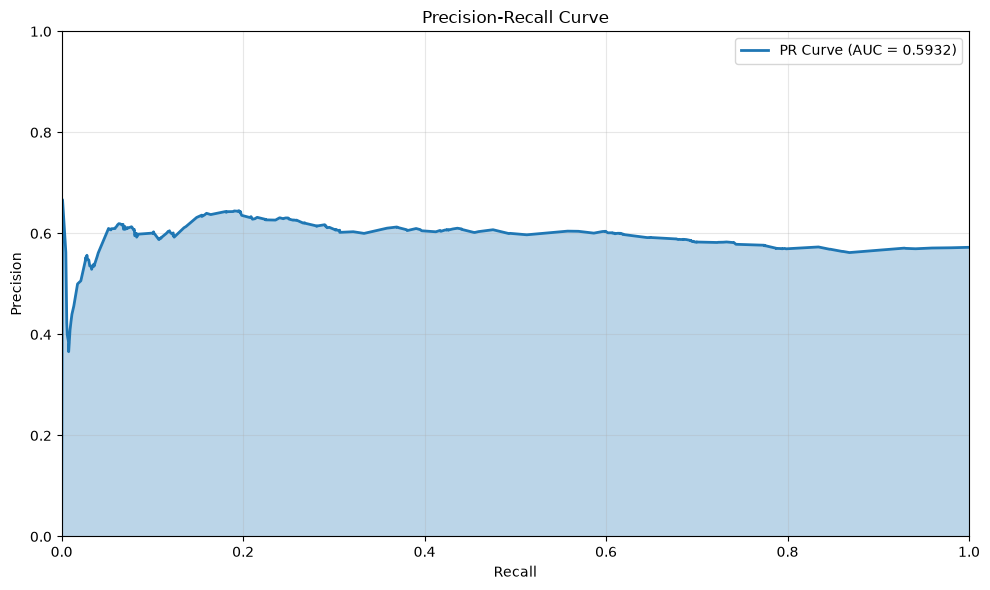

AUPRC (Area Under Precision-Recall Curve): 0.5932
Positive rate: ,  0.572316
Average of training data: 0.4876


In [ ]:
# Get prediction probabilities
y_pred_proba = model.predict_proba(X_test)[:, 1]

# Calculate precision-recall curve
precision, recall, thresholds = precision_recall_curve(y_test, y_pred_proba)

# Calculate area under curve (AUPRC)
pr_auc = auc(recall, precision)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(recall, precision, linewidth=2, label=f'PR Curve (AUC = {pr_auc:.4f})')
plt.fill_between(recall, precision, alpha=0.3)

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.grid(True, alpha=0.3)
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.tight_layout()
plt.show()

print(f"AUPRC (Area Under Precision-Recall Curve): {pr_auc:.4f}")
print(f"Average of testing data: , {y_test.mean(): 4f}")
print(f"Average of training data: {y_train.mean():.4f}")

In [6]:
from sklearn.metrics import precision_score, recall_score

for threshold in [0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80]:
    pred = (y_pred_proba >= threshold).astype(int)

    print(
        f"{threshold:.2f} | "
        f"signals={pred.sum():4d} | "
        f"precision={precision_score(y_test, pred):.3f} | "
        f"recall={recall_score(y_test, pred):.3f}"
    )

0.50 | signals=2290 | precision=0.586 | recall=0.694
0.55 | signals=2121 | precision=0.592 | recall=0.649
0.60 | signals=1957 | precision=0.600 | recall=0.607
0.65 | signals=1353 | precision=0.607 | recall=0.424
0.70 | signals= 570 | precision=0.644 | recall=0.190
0.75 | signals= 217 | precision=0.608 | recall=0.068
0.80 | signals=  92 | precision=0.543 | recall=0.026


In [7]:
# Test best found thresholds on test set
for name, threshold in [("Conservative", 0.60)]:
    y_pred_threshold = (y_pred_proba >= threshold).astype(int)

    print(f"\n=== {name} (threshold={threshold:.4f}) ===")
    print(f"Trades generated: {y_pred_threshold.sum()}")
    print(f"Precision: {precision_score(y_test, y_pred_threshold):.4f}")
    print(f"Recall: {recall_score(y_test, y_pred_threshold):.4f}")

    # Winners / losers
    tp = ((y_pred_threshold == 1) & (y_test == 1)).sum()
    fp = ((y_pred_threshold == 1) & (y_test == 0)).sum()

    print(f"Winners: {tp}, Losers: {fp}")

    # Get actual returns for the selected trades
    test_returns = df.loc[y_test.index, "target_return"]

    selected_returns = test_returns[y_pred_threshold == 1]

    print(f"Total return: {selected_returns.sum():.2f}%")
    print(f"Average return per trade: {selected_returns.mean():.2f}%")
    print(f"Median return per trade: {selected_returns.median():.2f}%")


=== Conservative (threshold=0.6000) ===
Trades generated: 1957
Precision: 0.6004
Recall: 0.6072
Winners: 1175, Losers: 782
Total return: 1462.09%
Average return per trade: 0.75%
Median return per trade: 0.51%


Max overlapping signal days: 3 -> RISK_FRACTION = 0.333
Avg exposure: 57% of equity


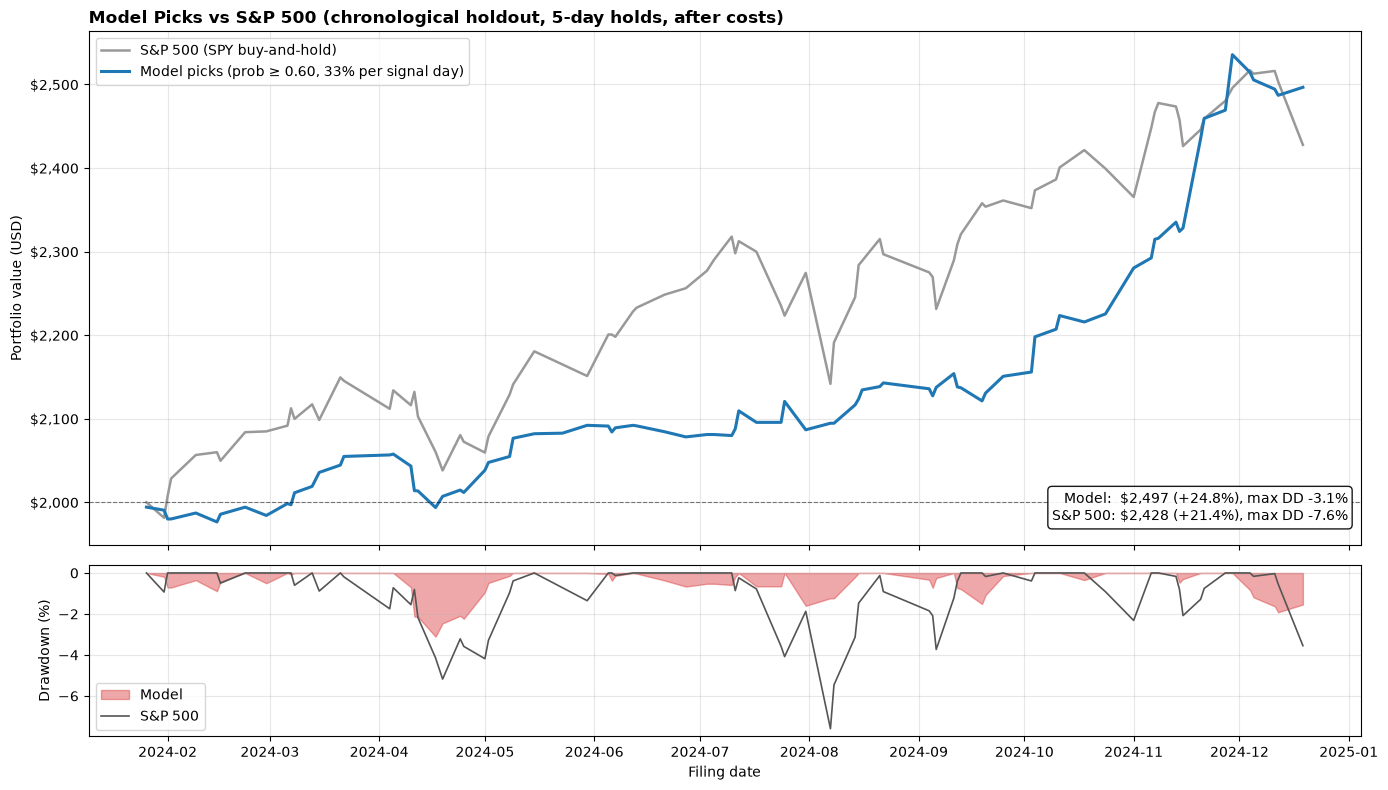

In [ ]:
# pip install yfinance   (if you don't have it)
import yfinance as yf
import matplotlib.pyplot as plt

THRESHOLD = 0.60
COST_PCT = 0.05          # 5 bps per trade, same units as target_return (percent)
HOLD_DAYS = 5
INITIAL_CAPITAL = 2_000

t = df.loc[y_test.index, ["filed_date", "target_return"]].copy()
t["prob"] = y_pred_proba
t["net"] = t["target_return"] - COST_PCT

# Measure the most signal days ever open at once, then size so that never exceeds 100% of equity
sel_days = t.loc[t["prob"] >= THRESHOLD, "filed_date"].drop_duplicates().sort_values()
bdays = pd.bdate_range(sel_days.min(), sel_days.max() + pd.Timedelta(days=15))
days_open = pd.Series(0, index=bdays)
for d in sel_days:
    i = bdays.searchsorted(d)
    days_open.iloc[i:i + HOLD_DAYS] += 1

RISK_FRACTION = 1 / days_open.max()
print(f"Max overlapping signal days: {days_open.max()} -> RISK_FRACTION = {RISK_FRACTION:.3f}")
print(f"Avg exposure: {days_open.mean() * RISK_FRACTION:.0%} of equity")

def equity_curve(sel):
    daily = sel.groupby("filed_date")["net"].mean().sort_index() / 100
    return INITIAL_CAPITAL * (1 + RISK_FRACTION * daily).cumprod()

# Common date axis: every filing date in the test period
dates = pd.DatetimeIndex(sorted(t["filed_date"].unique()))

# Model: sits in cash on days it takes no trade
eq_sel = equity_curve(t[t["prob"] >= THRESHOLD]).reindex(dates).ffill().fillna(INITIAL_CAPITAL)

# S&P 500 (SPY, dividend-adjusted), buy-and-hold over the same window
spy = yf.download("SPY", start=dates.min() - pd.Timedelta(days=7),
                  end=dates.max() + pd.Timedelta(days=7),
                  auto_adjust=True, progress=False)["Close"].squeeze()
spy = spy.reindex(spy.index.union(dates)).ffill().reindex(dates)
eq_spy = INITIAL_CAPITAL * spy / spy.iloc[0]

dd_sel = eq_sel / eq_sel.cummax() - 1
dd_spy = eq_spy / eq_spy.cummax() - 1

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(14, 8), sharex=True,
    gridspec_kw={"height_ratios": [3, 1]}
)

ax1.plot(eq_spy.index, eq_spy, color="#999999", linewidth=1.8, label="S&P 500 (SPY buy-and-hold)")
ax1.plot(eq_sel.index, eq_sel, color="#1f77b4", linewidth=2.2,
         label=f"Model picks (prob ≥ {THRESHOLD:.2f}, {RISK_FRACTION:.0%} per signal day)")
ax1.axhline(INITIAL_CAPITAL, color="black", linewidth=0.8, linestyle="--", alpha=0.5)
ax1.set_title("Model Picks vs S&P 500 (chronological holdout, 5-day holds, after costs)",
              loc="left", fontweight="bold")
ax1.set_ylabel("Portfolio value (USD)")
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax1.grid(True, alpha=0.3)
ax1.legend(loc="upper left")

stats = (
    f"Model:  ${eq_sel.iloc[-1]:,.0f} ({eq_sel.iloc[-1]/INITIAL_CAPITAL - 1:+.1%}), "
    f"max DD {dd_sel.min():.1%}\n"
    f"S&P 500: ${eq_spy.iloc[-1]:,.0f} ({eq_spy.iloc[-1]/INITIAL_CAPITAL - 1:+.1%}), "
    f"max DD {dd_spy.min():.1%}"
)
ax1.text(0.99, 0.04, stats, transform=ax1.transAxes, ha="right", va="bottom",
         fontsize=10, bbox=dict(boxstyle="round", facecolor="white", alpha=0.9))

ax2.fill_between(dd_sel.index, dd_sel * 100, 0, color="#d62728", alpha=0.4, label="Model")
ax2.plot(dd_spy.index, dd_spy * 100, color="#555555", linewidth=1.2, label="S&P 500")
ax2.set_ylabel("Drawdown (%)")
ax2.set_xlabel("Filing date")
ax2.grid(True, alpha=0.3)
ax2.legend(loc="lower left")

plt.tight_layout()
plt.show()
print("hello")